## Random Forest v2 — hold-out temporal com expurgo e Optuna otimizado por F1

Estratégia de balanceamento: undersampling.


In [1]:

# Celula 1: prepara o ambiente de trabalho para toda a analise.
# Mantem a mesma estrutura do notebook XGBoost para permitir comparacao justa.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    brier_score_loss,
    log_loss,
    ConfusionMatrixDisplay,
)

# Instala automaticamente o optuna apenas se ele nao estiver disponivel.
try:
    import optuna
except ImportError:
    import sys
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "optuna", "-q"])
    import optuna

# Instala automaticamente o optuna-dashboard apenas se ele nao estiver disponivel.
try:
    import optuna_dashboard
except ImportError:
    import sys
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "optuna-dashboard", "-q"])
    import optuna_dashboard

pd.set_option("display.max_columns", None)
print("Bibliotecas carregadas com sucesso.")



from imblearn.under_sampling import RandomUnderSampler


c:\Users\Sofhia\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Bibliotecas carregadas com sucesso.


In [2]:
# Celula 2: leitura da base e preparo das variaveis de entrada.
csv_path = Path("../../tabela_final/table_orders_holidays_ecommerce_events.csv")
df = pd.read_csv(csv_path)

target_col = "delivered_on_time"
if target_col not in df.columns:
    raise ValueError(f"A coluna alvo '{target_col}' nao foi encontrada no CSV.")

# =====================================================================
# 1. FEATURES DE LAST MILE JA CALCULADAS NA TABELA FINAL
# =====================================================================
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'], utc=True)
df['order_estimated_delivery_date'] = pd.to_datetime(df['order_estimated_delivery_date'], utc=True)
df['order_delivered_carrier_date'] = pd.to_datetime(df['order_delivered_carrier_date'], utc=True)

required_features = ["carrier_available_days", "delivery_time_per_km", "freight_per_kg", "product_density", "carrier_month"]
missing_features = [c for c in required_features if c not in df.columns]
if missing_features:
    raise ValueError(f"Features ausentes na tabela final: {missing_features}")
print("Pedidos já atrasados na coleta:", (df["carrier_available_days"] < 0).sum())

# Remover os casos onde a transportadora nunca pegou o pacote para evitar NaN no treino
df = df.dropna(subset=["carrier_available_days", "order_delivered_carrier_date", "order_delivered_customer_date"]).copy()

# =====================================================================
# 2. ORDENAÇÃO CRONOLÓGICA (Baseada no momento da coleta)
# =====================================================================
df = df.sort_values('order_delivered_carrier_date').reset_index(drop=True)

# Divide em treino/teste com split temporal (Passado treina, Futuro testa).
# Treino: ate Junho de 2018 | Teste: Julho de 2018 em diante.
date_col = df['order_delivered_carrier_date'].copy()
split_date = pd.to_datetime("2018-07-01", utc=True)

leakage_candidates = [
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "shipping_delay_hours",
    "delivery_time_days",
    "review_score",
]
leakage_cols = [c for c in leakage_candidates if c in df.columns]

# Separa previsores e alvo.
feature_cols = [c for c in df.columns if c != target_col and c not in leakage_cols]
X = df[feature_cols].copy()
# Inverte o alvo: atraso = 1, no prazo = 0.
y = (~df[target_col].astype(bool)).astype(int).copy()

colunas_remover = [
    "order_purchase_timestamp",
    "order_approved_at",
    "interval_code_delivered_carrier", # variável n ajudou no modelo
    "interval_code_delivered_customer",
    "order_estimated_delivery_date", # Ja usamos
    "shipping_limit_date",
    "delivered_on_time",
    "review_score",
    
    # --- FEATURES REDUNDANTES / BAIXA INFLUENCIA REMOVIDAS ---
    "is_holiday_in_7_days",
    "is_holiday_in_14_days",
    "had_holiday_7_days_ago",
    "had_holiday_14_days_ago",
    "holiday_at_purchase",
    "is_weekend",

    # --- TESTE: Remocao de cidades e category_name ---
    "customer_city",
    "seller_city",
    "category_name",
    # "same_city",  # Descomente se tambem quiser retirar a flag de mesma cidade


]

X = X.drop(columns=colunas_remover, errors='ignore')

cat_cols = []  # Mesma configuracao do XGBoost
# Verificacao explicita: RandomForestClassifier exige valores numericos e finitos.
non_numeric = X.select_dtypes(exclude=["number", "bool"]).columns.tolist()
if non_numeric:
    raise ValueError(f"Colunas nao numericas no RF: {non_numeric}. Ajuste a selecao/encoding em ambos os modelos.")
X = X.replace([np.inf, -np.inf], np.nan)
if X.isna().any().any():
    raise ValueError(f"Ha valores ausentes nas features: {X.columns[X.isna().any()].tolist()}. Trate-os na tabela final.")

train_mask = date_col < split_date
test_mask = date_col >= split_date

X_train = X[train_mask].copy()
y_train = y[train_mask].copy()
X_test = X[test_mask].copy()
y_test = y[test_mask].copy()

num_cols = list(X_train.columns)
scaler = None  # Random Forest nao necessita de normalizacao



Pedidos já atrasados na coleta: 0


In [3]:
# Celula 3: define funcoes e configuracoes da busca de hiperparametros.
# A avaliacao desta analise trata "atraso" como classe positiva (1).
def metricas_atraso(y_true, y_pred_atraso, y_proba_atraso):
    return {
        "accuracy_atraso": accuracy_score(y_true, y_pred_atraso),
        "precision_atraso": precision_score(y_true, y_pred_atraso, zero_division=0),
        "recall_atraso": recall_score(y_true, y_pred_atraso, zero_division=0),
        "f1_atraso": f1_score(y_true, y_pred_atraso, zero_division=0),
        "f2_atraso": fbeta_score(y_true, y_pred_atraso, beta=2, zero_division=0),
        "roc_auc_atraso": roc_auc_score(y_true, y_proba_atraso),
        "pr_auc_atraso": average_precision_score(y_true, y_proba_atraso),
        "balanced_accuracy_atraso": balanced_accuracy_score(y_true, y_pred_atraso),
        "mcc_atraso": matthews_corrcoef(y_true, y_pred_atraso),
        "brier_score_atraso": brier_score_loss(y_true, y_proba_atraso),
        "log_loss_atraso": log_loss(y_true, y_proba_atraso),
    }


def metricas_gerais(y_true, y_pred, y_proba):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "PR-AUC": average_precision_score(y_true, y_proba),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Brier Score": brier_score_loss(y_true, y_proba),
        "Log Loss": log_loss(y_true, y_proba),
    }

# Configuracao do Optuna para busca de hiperparametros (Hold-out Temporal sem folds).
n_trials = 50
study_seed = 42
threshold_grid_tune = np.arange(0.05, 0.86, 0.01)

# Hold-out Temporal: divide X_train em Treino de Tuning (ate Abr/2018) e Validacao (Maio-Jun/2018)
# Expurga (purging) os pedidos do treino cuja entrega ocorreu a partir do inicio da validacao.
val_split_date = pd.to_datetime("2018-05-01", utc=True)
carrier_train_dates = pd.to_datetime(df.loc[X_train.index, "order_delivered_carrier_date"], utc=True)
customer_train_dates = pd.to_datetime(df.loc[X_train.index, "order_delivered_customer_date"], utc=True)

# Expurgo adicional na fronteira treino/teste (01/07/2018):
# pedidos coletados antes do teste mas entregues no periodo do teste nao entram no treinamento.
mask_cruzamento_teste = (carrier_train_dates < split_date) & (customer_train_dates >= split_date)
n_expurgados_teste = int(mask_cruzamento_teste.sum())
if n_expurgados_teste:
    X_train = X_train.loc[~mask_cruzamento_teste].copy()
    y_train = y_train.loc[~mask_cruzamento_teste].copy()
    carrier_train_dates = carrier_train_dates.loc[~mask_cruzamento_teste].copy()
    customer_train_dates = customer_train_dates.loc[~mask_cruzamento_teste].copy()

# 1. Identifica os registros de tuning e validacao com expurgo de sobreposicoes
tr_mask_tune = (carrier_train_dates < val_split_date) & (customer_train_dates < val_split_date)
va_mask_tune = (carrier_train_dates >= val_split_date)
n_expurgados_val = int(((carrier_train_dates < val_split_date) & (customer_train_dates >= val_split_date)).sum())

# 2. Atualiza X_train e y_train para conter estritamente a base limpa pos-expurgo (Treino Tuning + Validacao)
train_clean_mask = tr_mask_tune | va_mask_tune
X_train = X_train.loc[train_clean_mask].reset_index(drop=True)
y_train = y_train.loc[train_clean_mask].reset_index(drop=True)

carrier_train_dates = carrier_train_dates.loc[train_clean_mask].reset_index(drop=True)
customer_train_dates = customer_train_dates.loc[train_clean_mask].reset_index(drop=True)

# Indices relativos ao novo X_train
tr_idx = np.where((carrier_train_dates < val_split_date).values)[0]
va_idx = np.where((carrier_train_dates >= val_split_date).values)[0]

# Vetor binario: 1 = atraso, 0 = nao atraso.
y_train_atraso = y_train.values

# Coletas do teste para exibicao das datas
carrier_test_dates = pd.to_datetime(df.loc[X_test.index, "order_delivered_carrier_date"], utc=True)

# Estatisticas revisadas e perfeitamente consistentes
qtd_tr_tune = len(tr_idx)
atrasos_tr_tune = int((y_train.iloc[tr_idx] == 1).sum())

qtd_va_tune = len(va_idx)
atrasos_va_tune = int((y_train.iloc[va_idx] == 1).sum())

qtd_treino = len(X_train)  # Exatamente qtd_tr_tune + qtd_va_tune
pos_count = int((y_train == 1).sum())  # Exatamente atrasos_tr_tune + atrasos_va_tune

qtd_teste = len(X_test)
total_linhas = qtd_treino + qtd_teste



In [4]:
print("=" * 105)
print("DISTRIBUIÇÃO DOS DADOS APÓS EXPURGO DAS SOBREPOSIÇÕES TEMPORAIS")
print("=" * 105)
print(f"Total de registros disponíveis: Linhas: {total_linhas:,} | Colunas: {X.shape[1]}\n")

print(f" - Pedidos expurgados por sobreposicao com o teste: {n_expurgados_teste:,}\n")

print("1. SEPARAÇÃO GERAL: TREINO COMPLETO vs. TESTE INDEPENDENTE (Corte: 01/07/2018)")
print("-" * 105)
print(f" - Treino Completo (Modelo Final): {qtd_treino:,} pedidos ({qtd_treino/total_linhas:.2%} da base)")
print(f"   * Janela de Coleta: {carrier_train_dates.min().strftime('%d/%m/%Y')} a {carrier_train_dates.max().strftime('%d/%m/%Y')}")
print(f"   * Atrasos no Treino Completo: {pos_count:,} pedidos ({(pos_count/qtd_treino):.2%})\n")
print(f" - Teste Independente (Avaliação Final): {qtd_teste:,} pedidos ({qtd_teste/total_linhas:.2%} da base)")
print(f"   * Janela de Coleta: {carrier_test_dates.min().strftime('%d/%m/%Y')} a {carrier_test_dates.max().strftime('%d/%m/%Y')}")
print(f"   * Atrasos no Teste: {(y_test == 1).sum():,} pedidos ({(y_test == 1).mean():.2%})\n")

print("2. SUBDIVISÃO DO TREINO: HOLD-OUT PARA OTIMIZAÇÃO (Corte: 01/05/2018)")
print("-" * 105)
print(f" - Treino de Tuning (Ajuste no Optuna): {qtd_tr_tune:,} pedidos ({qtd_tr_tune/total_linhas:.2%} da base | {qtd_tr_tune/qtd_treino:.2%} do treino)")
print(f"   * Janela de Coleta: {carrier_train_dates.iloc[tr_idx].min().strftime('%d/%m/%Y')} a {carrier_train_dates.iloc[tr_idx].max().strftime('%d/%m/%Y')}")
print(f"   * Atrasos no Treino de Tuning: {atrasos_tr_tune:,} pedidos ({(atrasos_tr_tune/qtd_tr_tune):.2%})")
print(f"   * Pedidos expurgados por invasão da validação: {n_expurgados_val:,} pedidos\n")
print(f" - Validação (Optuna & Seleção de Limiar): {qtd_va_tune:,} pedidos ({qtd_va_tune/total_linhas:.2%} da base | {qtd_va_tune/qtd_treino:.2%} do treino)")
print(f"   * Janela de Coleta: {carrier_train_dates.iloc[va_idx].min().strftime('%d/%m/%Y')} a {carrier_train_dates.iloc[va_idx].max().strftime('%d/%m/%Y')}")
print(f"   * Atrasos na Validação: {atrasos_va_tune:,} pedidos ({(atrasos_va_tune/qtd_va_tune):.2%})")
print("=" * 105)

X_test.head()


DISTRIBUIÇÃO DOS DADOS APÓS EXPURGO DAS SOBREPOSIÇÕES TEMPORAIS
Total de registros disponíveis: Linhas: 34,283 | Colunas: 23

 - Pedidos expurgados por sobreposicao com o teste: 0

1. SEPARAÇÃO GERAL: TREINO COMPLETO vs. TESTE INDEPENDENTE (Corte: 01/07/2018)
---------------------------------------------------------------------------------------------------------
 - Treino Completo (Modelo Final): 29,098 pedidos (84.88% da base)
   * Janela de Coleta: 08/10/2016 a 29/06/2018
   * Atrasos no Treino Completo: 1,367 pedidos (4.70%)

 - Teste Independente (Avaliação Final): 5,185 pedidos (15.12% da base)
   * Janela de Coleta: 02/07/2018 a 29/08/2018
   * Atrasos no Teste: 521 pedidos (10.05%)

2. SUBDIVISÃO DO TREINO: HOLD-OUT PARA OTIMIZAÇÃO (Corte: 01/05/2018)
---------------------------------------------------------------------------------------------------------
 - Treino de Tuning (Ajuste no Optuna): 23,988 pedidos (69.97% da base | 82.44% do treino)
   * Janela de Coleta: 08/10/2016

,carrier_month,holiday_at_carrier,days_since_last_holiday,days_until_next_holiday,ecommerce_event_at_carrier,days_since_last_ecommerce_event,days_until_next_ecommerce_event,is_ecommerce_event_in_7_days,is_ecommerce_event_in_14_days,had_ecommerce_event_7_days_ago,had_ecommerce_event_14_days_ago,purchase_hour,purchase_day_of_week,price,freight_value,product_weight_g,volume_cm3,distance_km,same_city,carrier_available_days,delivery_time_per_km,freight_per_kg,product_density
29098,7,0,32,7,0,20,41,0,0,0,0,15,6,58.99,13.07,200,3960.0,65.455,0,17,0.259720,65.350000,0.050505
29099,7,0,32,7,0,20,41,0,0,0,0,20,6,24.99,13.76,2350,10648.0,410.895,0,17,0.041373,5.855319,0.220699
29100,7,0,32,7,0,20,41,0,0,0,0,10,7,119.90,13.50,459,3276.0,284.356,0,21,0.073851,29.411765,0.140110
29101,7,0,32,7,0,20,41,0,0,0,0,8,7,49.00,13.00,250,640.0,220.486,0,18,0.081638,52.000000,0.390625
29102,7,0,32,7,0,20,41,0,0,0,0,14,6,106.00,17.95,3305,35100.0,114.112,0,11,0.096397,5.431165,0.094160


In [5]:
# Celula 4: busca de hiperparametros com Optuna + Hold-out Temporal (sem folds).
# Criterio de selecao e otimizacao: maior F1-score (cv_f1_atraso), com desempate por PR-AUC e Recall.
optuna_db_path = Path("optuna_rf_holdout_f1_v2.db").resolve()
study_storage = f"sqlite:///{optuna_db_path.as_posix()}"
study_name = "rf_holdout_lastmile_f1_v2"

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 300, step=50),
        "max_depth": trial.suggest_int("max_depth", 3, 18),
        "max_samples": trial.suggest_float("max_samples", 0.5, 0.8),
        "max_features": trial.suggest_float("max_features", 0.5, 0.8),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 20),
        "min_samples_split": trial.suggest_int("min_samples_split", 10, 50),
        "ccp_alpha": trial.suggest_float("ccp_alpha", 0.0, 0.002),
    }

    # 1. Extraímos treino e validação do Hold-out Temporal (sem sobreposição)
    X_tr, X_va = X_train.iloc[tr_idx], X_train.iloc[va_idx]
    y_tr, y_va = y_train.iloc[tr_idx], y_train.iloc[va_idx]

    # 2. Ajustamos os parâmetros do modelo (sem folds para comparação justa)
    mdl = RandomForestClassifier(
        random_state=1000 + trial.number * 10,
        n_jobs=-1,
        bootstrap=True,
        class_weight=None,
        **params,
    )
    rus = RandomUnderSampler(sampling_strategy="auto", random_state=42 + trial.number)
    X_fit, y_fit = rus.fit_resample(X_tr, y_tr)
    mdl.fit(X_fit, y_fit)

    # Probabilidade de atraso = classe positiva (1) na validacao.
    oof_proba_val = mdl.predict_proba(X_va)[:, 1]
    y_val_real = y_va.values

    pr_auc_i = float(average_precision_score(y_val_real, oof_proba_val))

    # Para cada conjunto de parametros, busca o melhor limiar de decisao maximizando F1.
    best_thr_i = 0.50
    best_f1_i = -1.0
    best_recall_i = -1.0
    best_precision_i = -1.0

    for thr in threshold_grid_tune:
        pred_atraso = (oof_proba_val >= thr).astype(int)
        precision_i = precision_score(y_val_real, pred_atraso, zero_division=0)
        recall_i = recall_score(y_val_real, pred_atraso, zero_division=0)
        f1_i = f1_score(y_val_real, pred_atraso, zero_division=0)

        if (f1_i > best_f1_i) or (np.isclose(f1_i, best_f1_i) and recall_i > best_recall_i) or (
            np.isclose(f1_i, best_f1_i) and np.isclose(recall_i, best_recall_i) and precision_i > best_precision_i
        ):
            best_f1_i = float(f1_i)
            best_recall_i = float(recall_i)
            best_precision_i = float(precision_i)
            best_thr_i = float(thr)

    trial.set_user_attr("best_threshold", best_thr_i)
    trial.set_user_attr("cv_pr_auc_atraso", pr_auc_i)
    trial.set_user_attr("cv_f1_atraso", best_f1_i)
    trial.set_user_attr("cv_recall_atraso", best_recall_i)
    trial.set_user_attr("cv_precision_atraso", best_precision_i)

    return best_f1_i  # Otimizar diretamente pela metrica F1 para comparacao justa entre modelos

sampler = optuna.samplers.TPESampler(seed=study_seed)
study = optuna.create_study(
    direction="maximize",
    sampler=sampler,
    study_name=study_name,
    storage=study_storage,
    load_if_exists=True,
)
study.optimize(objective, n_trials=n_trials, show_progress_bar=False)

best_trial = study.best_trial
best_params_v2 = best_trial.params
best_threshold_v2 = float(best_trial.user_attrs["best_threshold"])

tuning_rows = []
for t in study.trials:
    if t.value is None or t.state != optuna.trial.TrialState.COMPLETE:
        continue
    tuning_rows.append({
        "candidate": t.number + 1,
        "cv_f1_atraso": t.user_attrs.get("cv_f1_atraso", np.nan),
        "cv_pr_auc_atraso": t.user_attrs.get("cv_pr_auc_atraso", np.nan),
        "cv_recall_atraso": t.user_attrs.get("cv_recall_atraso", np.nan),
        "cv_precision_atraso": t.user_attrs.get("cv_precision_atraso", np.nan),
        "best_threshold": t.user_attrs.get("best_threshold", np.nan),
        "params": t.params,
    })

df_tuning = pd.DataFrame(tuning_rows).sort_values(
    ["cv_f1_atraso", "cv_pr_auc_atraso", "cv_recall_atraso", "cv_precision_atraso"], ascending=False
).reset_index(drop=True)



[I 2026-11-09 20:41:09,218] A new study created in RDB with name: rf_holdout_lastmile_f1_v2
[I 2026-11-09 20:41:10,216] Trial 0 finished with value: 0.3581081081081081 and parameters: {'n_estimators': 150, 'max_depth': 18, 'max_samples': 0.7195981825434216, 'max_features': 0.679597545259111, 'min_samples_leaf': 4, 'min_samples_split': 16, 'ccp_alpha': 0.00011616722433639892}. Best is trial 0 with value: 0.3581081081081081.
[I 2026-11-09 20:41:11,387] Trial 1 finished with value: 0.3151515151515151 and parameters: {'n_estimators': 300, 'max_depth': 12, 'max_samples': 0.7124217733388136, 'max_features': 0.5061753482887408, 'min_samples_leaf': 20, 'min_samples_split': 44, 'ccp_alpha': 0.00042467822135655234}. Best is trial 0 with value: 0.3581081081081081.
[I 2026-11-09 20:41:12,132] Trial 2 finished with value: 0.3207126948775056 and parameters: {'n_estimators': 100, 'max_depth': 5, 'max_samples': 0.5912726728878613, 'max_features': 0.6574269294896714, 'min_samples_leaf': 9, 'min_samples

In [6]:
print(f"Trials avaliados: {len(df_tuning)}")
print("Top 8 configuracoes pela validacao (F1 -> PR-AUC -> Recall):")
display(df_tuning.head(8))
print("\nMelhores hiperparametros encontrados (Otimizado por F1):")
for key, value in best_params_v2.items():
    print(f" - {key}: {value}")
print(f"Melhor limiar (Optuna - Foco F1): {best_threshold_v2:.2f}")
print(f"Study name: {study_name}")
print(f"Comando dashboard: optuna-dashboard {study_storage} --port 8080")


Trials avaliados: 50
Top 8 configuracoes pela validacao (F1 -> PR-AUC -> Recall):


,candidate,cv_f1_atraso,cv_pr_auc_atraso,cv_recall_atraso,cv_precision_atraso,best_threshold,params
0,41,0.381818,0.298627,0.384146,0.379518,0.80,"{'n_estimators': 150, 'max_depth': 6, 'max_sam..."
1,39,0.373832,0.294952,0.365854,0.382166,0.78,"{'n_estimators': 150, 'max_depth': 7, 'max_sam..."
2,38,0.369338,0.295069,0.323171,0.430894,0.81,"{'n_estimators': 150, 'max_depth': 4, 'max_sam..."
3,37,0.368098,0.289999,0.365854,0.370370,0.75,"{'n_estimators': 150, 'max_depth': 5, 'max_sam..."
4,30,0.365931,0.281119,0.353659,0.379085,0.81,"{'n_estimators': 150, 'max_depth': 5, 'max_sam..."
5,44,0.360000,0.291353,0.439024,0.305085,0.77,"{'n_estimators': 150, 'max_depth': 7, 'max_sam..."
6,1,0.358108,0.283215,0.323171,0.401515,0.83,"{'n_estimators': 150, 'max_depth': 18, 'max_sa..."
7,9,0.355828,0.281382,0.353659,0.358025,0.79,"{'n_estimators': 100, 'max_depth': 6, 'max_sam..."



Melhores hiperparametros encontrados (Otimizado por F1):
 - n_estimators: 150
 - max_depth: 6
 - max_samples: 0.5923975506873949
 - max_features: 0.6183636723433038
 - min_samples_leaf: 8
 - min_samples_split: 16
 - ccp_alpha: 0.0012236980807290008
Melhor limiar (Optuna - Foco F1): 0.80
Study name: rf_holdout_lastmile_f1_v2
Comando dashboard: optuna-dashboard sqlite:///C:/FACULDADE/tcc/backend/modelo/split-temporal/optuna_rf_holdout_f1_v2.db --port 8080


Metricas no teste (foco em atraso e F1-score):


,Teste
accuracy_atraso,0.7535
precision_atraso,0.2662
recall_atraso,0.8273
f1_atraso,0.4028
f2_atraso,0.5820
roc_auc_atraso,0.8651
pr_auc_atraso,0.4019
balanced_accuracy_atraso,0.7863
mcc_atraso,0.3714
brier_score_atraso,0.3755



Como interpretar as metricas:
- precision_atraso: entre os pedidos previstos como atraso, quantos realmente atrasaram.
- recall_atraso: entre os pedidos que realmente atrasaram, quantos o modelo conseguiu detectar.
- f1_atraso: media harmonica entre precision e recall.
- f2_atraso: semelhante ao F1, mas dando mais peso ao recall.
- roc_auc_atraso: capacidade de separar atraso vs nao atraso em todos os limiares.
- pr_auc_atraso: qualidade do trade-off precision x recall para a classe rara.


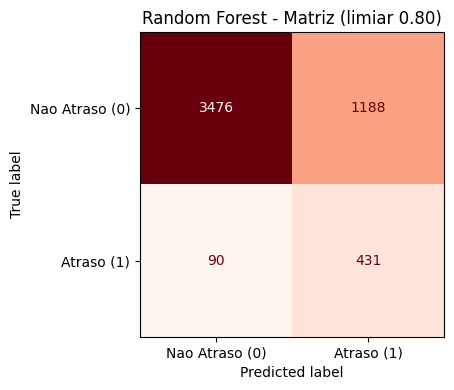

Resumo (teste):
- Limiar adotado: 0.80
- F1 atraso (Principal): 0.4028
- Precision atraso: 0.2662
- Recall atraso: 0.8273
- F2 atraso: 0.5820
- ROC-AUC atraso: 0.8651
- PR-AUC atraso: 0.4019


In [7]:

# Celula 5: treino final do Random Forest com os melhores hiperparametros + avaliacao no teste.
model_v2 = RandomForestClassifier(
    random_state=4242,
    n_jobs=-1,
    bootstrap=True,
    class_weight=None,  # Sem balanceamento
    **best_params_v2,
)

rus_final = RandomUnderSampler(sampling_strategy="auto", random_state=42)
X_fit_final, y_fit_final = rus_final.fit_resample(X_train, y_train)
model_v2.fit(X_fit_final, y_fit_final)

# Probabilidade de atraso (classe 1).
y_proba_v2_train = model_v2.predict_proba(X_train)[:, 1]
y_proba_v2_test = model_v2.predict_proba(X_test)[:, 1]

# Mesmo threshold otimizado na validacao temporal.
y_pred_v2_train = (y_proba_v2_train >= best_threshold_v2).astype(int)
y_pred_v2_test = (y_proba_v2_test >= best_threshold_v2).astype(int)

res_v2_train = metricas_atraso(y_train, y_pred_v2_train, y_proba_v2_train)
res_v2_test = metricas_atraso(y_test, y_pred_v2_test, y_proba_v2_test)
metricas_treino_v2 = metricas_gerais(y_train, y_pred_v2_train, y_proba_v2_train)
metricas_teste_v2 = metricas_gerais(y_test, y_pred_v2_test, y_proba_v2_test)

print("Metricas no teste (foco em atraso e F1-score):")
display(pd.DataFrame(pd.Series(res_v2_test, name="Teste")).round(4))

print("\nComo interpretar as metricas:")
print("- precision_atraso: entre os pedidos previstos como atraso, quantos realmente atrasaram.")
print("- recall_atraso: entre os pedidos que realmente atrasaram, quantos o modelo conseguiu detectar.")
print("- f1_atraso: media harmonica entre precision e recall.")
print("- f2_atraso: semelhante ao F1, mas dando mais peso ao recall.")
print("- roc_auc_atraso: capacidade de separar atraso vs nao atraso em todos os limiares.")
print("- pr_auc_atraso: qualidade do trade-off precision x recall para a classe rara.")

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_v2_test,
    cmap="Reds",
    ax=ax,
    colorbar=False,
    display_labels=["Nao Atraso (0)", "Atraso (1)"],
)
ax.set_title(f"Random Forest - Matriz (limiar {best_threshold_v2:.2f})")
plt.tight_layout()
plt.show()

print("Resumo (teste):")
print(f"- Limiar adotado: {best_threshold_v2:.2f}")
print(f"- F1 atraso (Principal): {res_v2_test['f1_atraso']:.4f}")
print(f"- Precision atraso: {res_v2_test['precision_atraso']:.4f}")
print(f"- Recall atraso: {res_v2_test['recall_atraso']:.4f}")
print(f"- F2 atraso: {res_v2_test['f2_atraso']:.4f}")
print(f"- ROC-AUC atraso: {res_v2_test['roc_auc_atraso']:.4f}")
print(f"- PR-AUC atraso: {res_v2_test['pr_auc_atraso']:.4f}")
# print(f"- R2 atraso: {res_v2_test['r2_atraso']:.4f}")


In [8]:
# Celula 6: tabelas de metricas de atraso (classe 1).
print("=" * 120)
print("METRICAS DE ATRASO (CLASSE 1)")
print("=" * 120)

print("\n(Accuracy, Precision, Recall, F1, F2, ROC-AUC, PR-AUC, Balanced Accuracy, MCC, Brier Score, Log Loss)")

print("\n" + "-" * 120)
print("TREINO (ATRASO)")
print("-" * 120)
df_v2_train_atraso = pd.DataFrame(pd.Series(res_v2_train, name="Treino"))
display(df_v2_train_atraso.round(4))

print("\n" + "-" * 120)
print("TESTE (ATRASO)")
print("-" * 120)
df_v2_test_atraso = pd.DataFrame(pd.Series(res_v2_test, name="Teste"))
display(df_v2_test_atraso.round(4))

# ============================================================================
# RESUMO
# ============================================================================
print("RESUMO\n")
print("─" * 120 + "\n")
print(f"  Limiar utilizado: {best_threshold_v2:.2f}")
print(
    f"  Treino - Accuracy: {metricas_treino_v2['Accuracy']:.4f}, ROC-AUC: {metricas_treino_v2['ROC-AUC']:.4f}, "
    f"Precision (Atraso): {res_v2_train['precision_atraso']:.4f}, Recall (Atraso): {res_v2_train['recall_atraso']:.4f}"
)
print(
    f"  Teste  - Accuracy: {metricas_teste_v2['Accuracy']:.4f}, ROC-AUC: {metricas_teste_v2['ROC-AUC']:.4f},"
    f"Precision (Atraso): {res_v2_test['precision_atraso']:.4f}, Recall (Atraso): {res_v2_test['recall_atraso']:.4f}"
)


METRICAS DE ATRASO (CLASSE 1)

(Accuracy, Precision, Recall, F1, F2, ROC-AUC, PR-AUC, Balanced Accuracy, MCC, Brier Score, Log Loss)

------------------------------------------------------------------------------------------------------------------------
TREINO (ATRASO)
------------------------------------------------------------------------------------------------------------------------


,Treino
accuracy_atraso,0.9509
precision_atraso,0.4670
recall_atraso,0.3204
f1_atraso,0.3800
f2_atraso,0.3419
roc_auc_atraso,0.8403
pr_auc_atraso,0.3632
balanced_accuracy_atraso,0.6512
mcc_atraso,0.3622
brier_score_atraso,0.1663



------------------------------------------------------------------------------------------------------------------------
TESTE (ATRASO)
------------------------------------------------------------------------------------------------------------------------


,Teste
accuracy_atraso,0.7535
precision_atraso,0.2662
recall_atraso,0.8273
f1_atraso,0.4028
f2_atraso,0.5820
roc_auc_atraso,0.8651
pr_auc_atraso,0.4019
balanced_accuracy_atraso,0.7863
mcc_atraso,0.3714
brier_score_atraso,0.3755


RESUMO

────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

  Limiar utilizado: 0.80
  Treino - Accuracy: 0.9509, ROC-AUC: 0.8403, Precision (Atraso): 0.4670, Recall (Atraso): 0.3204
  Teste  - Accuracy: 0.7535, ROC-AUC: 0.8651,Precision (Atraso): 0.2662, Recall (Atraso): 0.8273


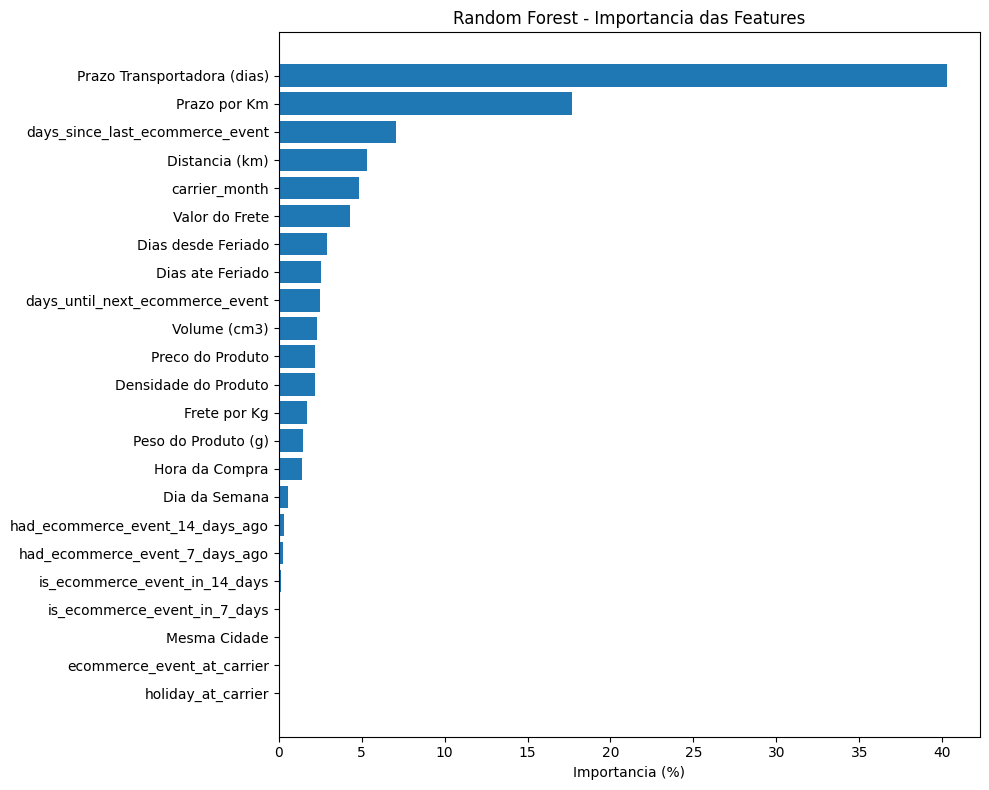


=== Resumo de importancia ===
  Prazo Transportadora (dias)               40.27%
  Prazo por Km                              17.66%
  days_since_last_ecommerce_event            7.07%
  Distancia (km)                             5.30%
  carrier_month                              4.86%
  Valor do Frete                             4.29%
  Dias desde Feriado                         2.92%
  Dias ate Feriado                           2.53%
  days_until_next_ecommerce_event            2.50%
  Volume (cm3)                               2.32%
  Preco do Produto                           2.17%
  Densidade do Produto                       2.16%
  Frete por Kg                               1.72%
  Peso do Produto (g)                        1.45%
  Hora da Compra                             1.38%
  Dia da Semana                              0.59%
  had_ecommerce_event_14_days_ago            0.30%
  had_ecommerce_event_7_days_ago             0.25%
  is_ecommerce_event_in_14_days              0.11%


In [9]:

# Celula Extra: Importancia das Features do Random Forest.
import matplotlib.pyplot as plt
import pandas as pd

df_imp = pd.DataFrame({
    "feature": X_train.columns,
    "importance": model_v2.feature_importances_,
}).sort_values("importance", ascending=True)

df_imp["importance_pct"] = df_imp["importance"] / df_imp["importance"].sum() * 100

rename_map = {
    "carrier_available_days": "Prazo Transportadora (dias)",
    "distance_km": "Distancia (km)",
    "freight_value": "Valor do Frete",
    "price": "Preco do Produto",
    "product_weight_g": "Peso do Produto (g)",
    "volume_cm3": "Volume (cm3)",
    "same_city": "Mesma Cidade",
    "seller_city_encoded": "Cidade do Vendedor (Target Encoded)",
    "customer_city_encoded": "Cidade do Cliente (Target Encoded)",
    "delivery_time_per_km": "Prazo por Km",
    "freight_per_kg": "Frete por Kg",
    "product_density": "Densidade do Produto",
    "purchase_hour": "Hora da Compra",
    "purchase_day_of_week": "Dia da Semana",
    "category_name_encoded": "Categoria do Produto",
    "days_until_next_holiday": "Dias ate Feriado",
    "days_since_last_holiday": "Dias desde Feriado",
    "purchase_month": "Mes da Compra",
}
df_imp["label"] = df_imp["feature"].map(rename_map).fillna(df_imp["feature"])

plt.figure(figsize=(10, 8))
plt.barh(df_imp["label"], df_imp["importance_pct"])
plt.xlabel("Importancia (%)")
plt.title("Random Forest - Importancia das Features")
plt.tight_layout()
plt.show()

print("\n=== Resumo de importancia ===")
df_imp_sorted = df_imp.sort_values("importance_pct", ascending=False)
for _, row in df_imp_sorted.iterrows():
    print(f"  {row['label']:40s} {row['importance_pct']:6.2f}%")


In [10]:
# Célula de exportação para deploy: modelo + pré-processamento completo.
# A API prevê no momento da coleta pela transportadora e recebe somente dados brutos.
import pickle

raw_columns = [
    "purchase_date", "purchase_time", "carrier_datetime", "estimated_delivery_datetime",
    "price", "freight_value", "product_weight_g", "height_cm", "width_cm", "length_cm",
    "distance_km", "same_city", "customer_city", "seller_city", "category_name",
]

artefato_modelo = {
    "modelo": model_v2,
    "balanceamento": best_balanceamento_v2,
    "hiperparametros": best_params_v2,
    "limiar": float(best_threshold_v2),
    "feature_names": list(X_train.columns),
    "num_cols": num_cols,
    "cat_cols": cat_cols,
    "scaler": scaler,
    "schema_version": 4,
    "inference_moment": "carrier_collection",
    "raw_columns": raw_columns,
    "ecommerce_events": [
        "mothers_day", "fathers_day", "children_day",
        "black_friday", "cyber_monday", "christmas",
    ],
}

with open("random_forest_lastmile_model.pkl", "wb") as file:
    pickle.dump(artefato_modelo, file)

# CSV bruto para testar o mesmo contrato usado pela tela individual e pelo lote.
# Amostra organica e balanceada com 40% de atrasos (target=1) diluidos no tempo.
n_registros = 150
n_atrasos = int(n_registros * 0.40)   # 60 pedidos que atrasaram
n_no_prazo = n_registros - n_atrasos  # 90 pedidos no prazo

df_test_full = df.loc[test_mask].copy()
df_test_full["target_real_atraso"] = y_test.values

df_atrasos = df_test_full[df_test_full["target_real_atraso"] == 1]
df_no_prazo = df_test_full[df_test_full["target_real_atraso"] == 0]

# 1. 60 atrasos distribuidos uniformemente ao longo do periodo de teste
idx_atrasos = np.round(np.linspace(0, len(df_atrasos) - 1, n_atrasos)).astype(int)
selected_atrasos = df_atrasos.iloc[idx_atrasos]

# 2. 90 pedidos no prazo pareados temporalmente para diluir organicamente os atrasos
used_indices = set()
selected_no_prazo_indices = []

for dt in selected_atrasos["order_delivered_carrier_date"]:
    diffs = (df_no_prazo["order_delivered_carrier_date"] - dt).abs()
    for c in diffs.sort_values().index:
        if c not in used_indices:
            used_indices.add(c)
            selected_no_prazo_indices.append(c)
            break

for dt in selected_atrasos["order_delivered_carrier_date"][::2]:
    if len(selected_no_prazo_indices) >= n_no_prazo:
        break
    diffs = (df_no_prazo["order_delivered_carrier_date"] - dt).abs()
    for c in diffs.sort_values().index:
        if c not in used_indices:
            used_indices.add(c)
            selected_no_prazo_indices.append(c)
            break

selected_no_prazo = df_no_prazo.loc[selected_no_prazo_indices]

# 3. Concatena e ordena estritamente por ordem cronologica da coleta pela transportadora
test_rows = pd.concat([selected_atrasos, selected_no_prazo]).sort_values("order_delivered_carrier_date").reset_index(drop=True)

df_export = pd.DataFrame({
    "purchase_date": test_rows["order_purchase_timestamp"].dt.strftime("%Y-%m-%d"),
    "purchase_time": test_rows["order_purchase_timestamp"].dt.strftime("%H:%M"),
    "carrier_datetime": test_rows["order_delivered_carrier_date"].dt.strftime("%Y-%m-%dT%H:%M"),
    "estimated_delivery_datetime": test_rows["order_estimated_delivery_date"].dt.strftime("%Y-%m-%dT%H:%M"),
    "price": test_rows["price"],
    "freight_value": test_rows["freight_value"],
    "product_weight_g": test_rows["product_weight_g"],
    # A base não possui dimensões individuais; 1 × 1 × volume preserva o volume original.
    "height_cm": 1.0,
    "width_cm": 1.0,
    "length_cm": test_rows["volume_cm3"],
    "distance_km": test_rows["distance_km"],
    "same_city": test_rows["same_city"],
    "customer_city": test_rows["customer_city"].fillna("Unknown"),
    "seller_city": test_rows["seller_city"].fillna("Unknown"),
    "category_name": test_rows["category_name"].fillna("Unknown"),
    "target_real_atraso": test_rows["target_real_atraso"].values,
})

nome_arquivo_csv = f"amostra_teste_rf_{n_registros}_pedidos.csv"
df_export.to_csv(nome_arquivo_csv, index=False)
df_export.to_csv("amostra_teste_rf_100_pedidos.csv", index=False) # Compatibilidade

print("[Exportação] Artefato completo salvo: random_forest_lastmile_model.pkl")
print(f"[Exportação] CSV bruto salvo: {nome_arquivo_csv} ({len(df_export)} pedidos: {df_export['target_real_atraso'].sum()} atrasos ({df_export['target_real_atraso'].mean():.0%}) e {(df_export['target_real_atraso'] == 0).sum()} no prazo)")

NameError: name 'best_balanceamento_v2' is not defined